# 03 Turn every wafer into 14 numbers

**What a feature is.** A model can't look at a picture. It needs a table of numbers, one row per
wafer, one column per thing measured and each of those columns is a feature.

**Why not just give it the 2704 squares?** A random forest is made of decision trees and a tree asks yes/no
questions about one column at a time, like "is square 1300 failed?". A Center pattern that sits two squares to
the left uses completely different squares, so to the tree it's a new pattern. It would need to see every
possible position to learn it.

**What to measure.** Instead of squares, I measure 14 numbers that describe how much
failed and where, the share of failed dies on the whole wafer, in 5 rings from the middle out, and in 8 slices
around the middle. A Center has a high middle ring wherever exactly it sits.


## 1. Rings and slices

**Why this step:** Every feature is measured inside a ring or a slice. So first I want to see what those areas look like.

**The problem:** Give every square of the 52 by 52 grid a ring number and a slice number.

**How:** This is at the top of `wafer.py` \
`np.indices((52, 52))` gives two grids: the row number and the column number of every square.\
**Distance:** Pythagoras, `sqrt((row - 25.5)² + (col - 25.5)²)`, the distance of every square to the middle. With 52 squares there's no single middle square, it sits between square 25 and 26.\
**Ring:** the distance divided by 26.5 and times 5 gives 0 to just under 5 inside the wafer. `.astype(int)` cuts off the decimals, so 3.7 becomes ring 3. `np.minimum(..., 4)` puts the empty corners in ring 4 too.\
**Slice:** `np.arctan2` gives the angle of every square around the middle, from -180 to 180 degrees. Add 180, divide by 45 (360 / 8) and cut off the decimals: slice 0 to 7.

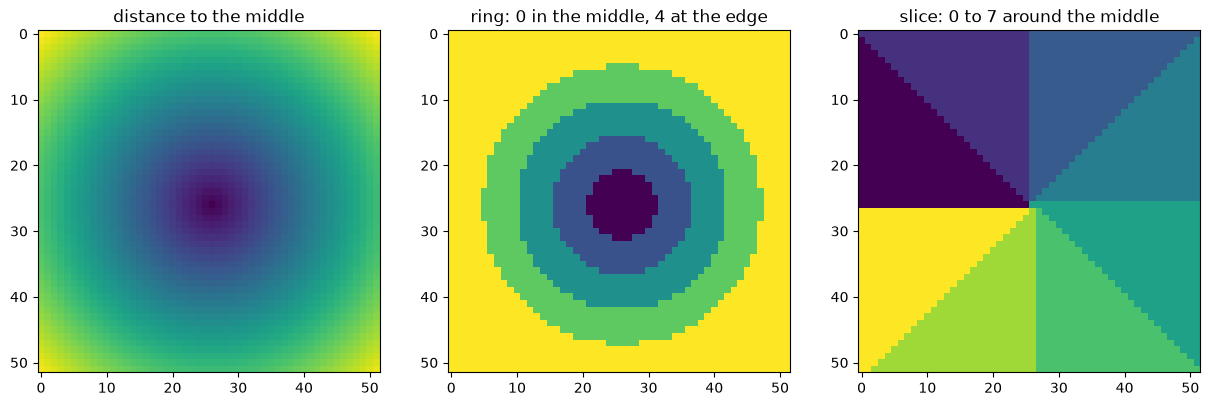

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import wafer

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(wafer.DISTANCE)
plt.title("distance to the middle")

plt.subplot(1, 3, 2)
plt.imshow(wafer.RING)
plt.title("ring: 0 in the middle, 4 at the edge")

plt.subplot(1, 3, 3)
plt.imshow(wafer.SECTOR)
plt.title("slice: 0 to 7 around the middle")

plt.show()

## 2. Check the features by hand

**Why this step:** If the numbers don't say what I think they say, the model learns from the wrong thing and I'd never know. A number I can't check is a number I can't defend.

**The problem:** Compute the 14 numbers for wafers whose pattern I know, and see if they make sense.

**How:** `wafer.share_failed_in(w, area)` counts the failed dies inside an area and divides by all dies in that area. `(w > 0) & area` means "a die, and inside this area": 0 is empty space and must not count as a good die. If an area has no dies, it gives 0 instead of nan, because a nan breaks training.\
`wafer.features(w)` calls that 14 times: once for the whole wafer, once per ring, once per slice.\
What I expect: a Center is high in ring 0 and low in ring 4. An Edge-Ring the other way round. An Edge-Loc is high at the edge but only in one or two slices. `np.round(..., 2)` keeps 2 decimals so it's readable.

In [2]:
split = np.load("output/split.npz")
maps = split["maps"]
labels = split["labels"]

for name in ["Center", "Edge-Ring", "Edge-Loc", "Scratch"]:
    # The first wafer with only this defect
    wanted = np.zeros(8, dtype=labels.dtype)
    wanted[wafer.DEFECTS.index(name)] = 1
    i = np.where((labels == wanted).all(axis=1))[0][0]

    f = wafer.features(maps[i])
    print(f"{name} (wafer {i}), share failed {f[0]:.2f}")
    print("  rings, middle to edge:", np.round(f[1:6], 2))
    print("  slices, around:       ", np.round(f[6:14], 2))

Center (wafer 11000), share failed 0.21
  rings, middle to edge: [0.38 0.27 0.21 0.19 0.18]
  slices, around:        [0.21 0.16 0.18 0.19 0.23 0.19 0.29 0.24]
Edge-Ring (wafer 25000), share failed 0.27
  rings, middle to edge: [0.17 0.2  0.2  0.22 0.4 ]
  slices, around:        [0.28 0.28 0.28 0.25 0.25 0.24 0.28 0.28]
Edge-Loc (wafer 24000), share failed 0.22
  rings, middle to edge: [0.21 0.17 0.21 0.21 0.26]
  slices, around:        [0.16 0.22 0.2  0.29 0.26 0.26 0.19 0.19]
Scratch (wafer 35890), share failed 0.21
  rings, middle to edge: [0.22 0.18 0.2  0.2  0.22]
  slices, around:        [0.18 0.18 0.19 0.24 0.23 0.21 0.24 0.18]


**What you should see:** The 14 numbers for four wafers whose pattern I know. Check them against what I expect: is
the Center highest in the middle ring, the Edge-Ring in the outer ring, the Edge-Loc high in only one or two slices,
and what does the Scratch do? Also look at the level under the pattern: failed dies outside the pattern are
background noise. If something here looks wrong, I fix it now, not after training.

## 3. How long will all of them take?

**Why this step:** Running `features()` on 36,890 wafers could take a while. Knowing that before I start saves waiting blind.

**The problem:** Time 500 wafers, then work out the time for all of them.

**How:** `time.perf_counter()` gives the time in seconds. Take it before and after, and subtract. `wafer.feature_table(maps)` runs `features()` on every wafer in a loop and stacks the rows into one table.

In [3]:
start = time.perf_counter()
part = wafer.feature_table(maps[:500])
seconds = time.perf_counter() - start

print(f"{seconds:.2f} s for 500 wafers")
print(f"{seconds / 500 * 1000:.2f} ms per wafer")
print(f"All {len(maps):,} wafers: about {seconds / 500 * len(maps):.0f} seconds")

0.06 s for 500 wafers
0.12 ms per wafer
All 36,890 wafers: about 5 seconds


**What you should see:** The time for 500 wafers, per wafer, and an estimate for all of them.

## 4. The feature table for all three parts

**Why this step:** This table is what the model learns from. Every part goes through the same function, so training and test are measured in exactly the same way. If they weren't, the test score would mean nothing.

**The problem:** Make `X_train`, `X_val` and `X_test`, and the matching answers `y_train`, `y_val`, `y_test`.

**How:** `X` is the usual name for "the input", the features. `y` is "the answers", the labels. `maps[train_idx]` picks the training wafers, then `feature_table` turns them into rows of 14.

In [4]:
train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

# The inputs: 14 numbers per wafer
X_train = wafer.feature_table(maps[train_idx])
X_val = wafer.feature_table(maps[val_idx])
X_test = wafer.feature_table(maps[test_idx])

# The answers: the 8 positions per wafer
y_train = labels[train_idx]
y_val = labels[val_idx]
y_test = labels[test_idx]

print("Training:", X_train.shape, "answers", y_train.shape)
print("Validation:", X_val.shape, "answers", y_val.shape)
print("Test:", X_test.shape, "answers", y_test.shape)

Training: (25822, 14) answers (25822, 8)
Validation: (5533, 14) answers (5533, 8)
Test: (5535, 14) answers (5535, 8)


**What you should see:** Every part has 14 columns, and as many rows as notebook 02 put in it. Every row is one
wafer, every column one feature.

## 5. Check the table

**Why this step:** A nan or a number outside 0 to 1 would mean a bug in the features, and the forest would train on garbage without complaining.

**The problem:** Make sure there are no missing values and every feature is a share between 0 and 1.

**How:** `np.isnan(X).any()` is True if any number is missing. `.min()` and `.max()` give the smallest and biggest.

In [5]:
for name, X in [("training", X_train), ("validation", X_val), ("test", X_test)]:
    assert not np.isnan(X).any(), "a missing value in the " + name + " features"
    assert X.min() >= 0 and X.max() <= 1, "a feature outside 0 to 1 in " + name
    print(f"{name}: no missing values, everything between {X.min():.2f} and {X.max():.2f}")

training: no missing values, everything between 0.00 and 1.00
validation: no missing values, everything between 0.00 and 1.00
test: no missing values, everything between 0.00 and 1.00


**What you should see:** Three lines: no missing values, every feature between 0 and 1.

## 6. Save the table

**Why this step:** Notebooks 04 to 09 load this file instead of computing the features again. The test features are saved here, but nobody looks at them until notebook 06.

**The problem:** Save all six arrays and the feature names in one file.

**How:** Same `np.savez_compressed` as in notebook 02.

In [6]:
np.savez_compressed(
    "output/features.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
    feature_names=np.array(wafer.FEATURE_NAMES),
)

print(f"Saved output/features.npz ({os.path.getsize('output/features.npz') / 1e6:.1f} MB)")

Saved output/features.npz (1.2 MB)


**What you should see:** "Saved output/features.npz" and its size, far smaller than the maps: 14 numbers per wafer
instead of 2704 squares.

## What this means for the next notebooks

The model will only ever see these 14 numbers. If two patterns give the same 14 numbers, the model can't tell them
apart, whatever settings I pick. That's the limit to keep in mind in notebooks 04 and 05: the baseline and the forest get the same 14 numbers.

## Functions in this notebook

| Function | What it does | Where to read more |
|---|---|---|
| `np.indices` | the row and column number of every square | [docs](https://numpy.org/doc/stable/reference/generated/numpy.indices.html) |
| `np.sqrt` | square root, for the distance | [docs](https://numpy.org/doc/stable/reference/generated/numpy.sqrt.html) |
| `np.minimum` | the smaller of two numbers, per square | [docs](https://numpy.org/doc/stable/reference/generated/numpy.minimum.html) |
| `np.arctan2 / np.degrees` | the angle around the middle, in degrees | [docs](https://numpy.org/doc/stable/reference/generated/numpy.arctan2.html) |
| `time.perf_counter` | a clock in seconds, for timing | [docs](https://docs.python.org/3/library/time.html#time.perf_counter) |
| `np.isnan` | True where a number is missing | [docs](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html) |
| `np.savez_compressed` | saves several arrays in one small file | [docs](https://numpy.org/doc/stable/reference/generated/numpy.savez_compressed.html) |